In [54]:
! pip install -q optuna
! pip install -q emoji
! pip install -q iterative-stratification

In [3]:
import pandas as pd
import numpy as np
import tqdm
from sklearn.model_selection import train_test_split
from datasets import Dataset, DatasetDict
from huggingface_hub import login
import torch
from torch import nn
import torch.nn.functional as F
from sklearn.utils.class_weight import compute_class_weight
import optuna
import ast
import re
import emoji
from transformers.utils import logging as hf_logging
import gc
import shutil
import random
import math
import html
from transformers import AutoTokenizer, Trainer, TrainingArguments, AutoModelForSequenceClassification, EarlyStoppingCallback, TrainerCallback, set_seed
from scipy.special import softmax
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, average_precision_score, classification_report
import datasets
import optuna
from huggingface_hub.utils import disable_progress_bars
from transformers.trainer_callback import PrinterCallback, ProgressCallback
from transformers.utils import logging as hf_logging
 
hf_logging.set_verbosity_error()          # laporan load model, warning transformers
hf_logging.disable_progress_bar()         # "Writing model shards", "Loading weights"
disable_progress_bars()                   # progress bar download dari Hugging Face Hub
datasets.disable_progress_bars()          # progress bar "Map"
optuna.logging.set_verbosity(optuna.logging.WARNING)   # log bawaan Optuna per trial

In [4]:
df = pd.read_csv("/kaggle/input/datasets/audreytheodoraphang/thesis-full/thesis_full.csv")

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27833 entries, 0 to 27832
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   text_id                        27833 non-null  object
 1   annotators_id                  27833 non-null  object
 2   text                           27832 non-null  object
 3   topic                          27833 non-null  object
 4   is_noise_or_spam_text          27833 non-null  object
 5   toxicity                       27833 non-null  object
 6   polarized                      27833 non-null  object
 7   profanity_obscenity            27833 non-null  object
 8   threat_incitement_to_violence  27833 non-null  object
 9   insults                        27833 non-null  object
 10  identity_attack                27833 non-null  object
 11  sexually_explicit              27833 non-null  object
 12  key                            27833 non-null  object
 13  c

In [6]:
df_main = df.copy()

In [7]:
cols = [
'is_noise_or_spam_text',
'toxicity',
'polarized',
'profanity_obscenity',
'threat_incitement_to_violence',
'insults',
'identity_attack',
'sexually_explicit'
]

for col in cols:
    df_main[col] = df_main[col].apply(lambda x: ast.literal_eval(x) if isinstance(x,str) else x)

In [8]:
df_main.iloc[5389]

text_id                                                                     1-6084
annotators_id                                                    ['20', '5', '33']
text                             Sosialisasi dan Edukasi Pasar Modal Terpadu Ha...
topic                                                                        Syiah
is_noise_or_spam_text                                                  ([0, 1], 0)
toxicity                                                                 [0, 0, 0]
polarized                                                                [0, 0, 0]
profanity_obscenity                                                      [0, 0, 0]
threat_incitement_to_violence                                            [0, 0, 0]
insults                                                                  [0, 0, 0]
identity_attack                                                          [0, 0, 0]
sexually_explicit                                                        [0, 0, 0]
key 

In [9]:
df_main['is_noise_or_spam_text'].iloc[5389] = [0, 1, 0]

/tmp/ipykernel_264/1462503684.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df_main['is_noise_or_spam_text'].iloc[5389] = [0, 1, 0]


In [10]:
for col in cols:
    for idx, x in df_main[col].items():
        try:
            for i in x:
                int(i)
        except Exception as e:
            print(f"Column: {col}")
            print(f"Row: {idx}")
            print("Cell:", x)
            print("Cell type:", type(x))
            print("Element types:", [type(i) for i in x])
            raise

In [11]:
print(cols)
cols2 = cols
cols2.remove('polarized')
print(cols2)

['is_noise_or_spam_text', 'toxicity', 'polarized', 'profanity_obscenity', 'threat_incitement_to_violence', 'insults', 'identity_attack', 'sexually_explicit']
['is_noise_or_spam_text', 'toxicity', 'profanity_obscenity', 'threat_incitement_to_violence', 'insults', 'identity_attack', 'sexually_explicit']


In [12]:
def majority_vote(x):
    x = [int(i) for i in x]
    return round(sum(x)/len(x))

for col in cols2:
    df_main[col] = df_main[col].apply(majority_vote)

In [13]:
df_main = df_main[df_main['is_noise_or_spam_text'] == 0]
df_main = df_main.dropna()
df_main.isnull().sum()

text_id                          0
annotators_id                    0
text                             0
topic                            0
is_noise_or_spam_text            0
toxicity                         0
polarized                        0
profanity_obscenity              0
threat_incitement_to_violence    0
insults                          0
identity_attack                  0
sexually_explicit                0
key                              0
cleaned_text                     0
processed_text                   0
dtype: int64

In [14]:
df_main.info()

<class 'pandas.core.frame.DataFrame'>
Index: 26375 entries, 0 to 27832
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   text_id                        26375 non-null  object
 1   annotators_id                  26375 non-null  object
 2   text                           26375 non-null  object
 3   topic                          26375 non-null  object
 4   is_noise_or_spam_text          26375 non-null  int64 
 5   toxicity                       26375 non-null  int64 
 6   polarized                      26375 non-null  object
 7   profanity_obscenity            26375 non-null  int64 
 8   threat_incitement_to_violence  26375 non-null  int64 
 9   insults                        26375 non-null  int64 
 10  identity_attack                26375 non-null  int64 
 11  sexually_explicit              26375 non-null  int64 
 12  key                            26375 non-null  object
 13  cleane

In [15]:
x = df_main["polarized"].iloc[0]
print(type(x), repr(x))

<class 'list'> ['0', '0']


In [16]:
df_main["polarization_list"] = df_main["polarized"].apply(lambda xs: [int(v) for v in xs])
df_main["pol_avg"] = df_main["polarization_list"].apply(lambda xs: float(np.mean(xs)))

print(df_main[["polarized", "pol_avg"]].head())

   polarized   pol_avg
0     [0, 0]  0.000000
1     [1, 1]  1.000000
2  [0, 0, 0]  0.000000
3  [1, 0, 0]  0.333333
4     [1, 1]  1.000000


In [17]:
SOURCE_COL = "cleaned_text"

for c in [SOURCE_COL]:
    if c in df.columns:
        n = df[c].fillna("").astype(str).map(emoji.emoji_count).gt(0).sum()
        print(f"{c:13s}: {n if n > 0 else 'None'}")

cleaned_text : 5083


In [18]:
EMOJI_LANG = "id"

In [19]:
# Emoticon teks -> kata. Hanya dicocokkan kalau berdiri sendiri (diapit spasi),
# supaya tidak salah tangkap di tengah kata.
emoticon_dict = {
    ":)": "senyum", ":-)": "senyum", "(:": "senyum", ":]": "senyum", "=)": "senyum",
    ":d": "tertawa", ":-d": "tertawa", "xd": "tertawa", "wkwk": "tertawa",
    ":(": "sedih", ":-(": "sedih", "):": "sedih", ":'(": "menangis",
    ";)": "berkedip", ";-)": "berkedip",
    ":p": "menjulurkan lidah", ":-p": "menjulurkan lidah",
    ":o": "terkejut", ":-o": "terkejut",
    ":/": "ragu", ":-/": "ragu",
    ">:(": "marah", "-_-": "kesal", "<3": "cinta", "</3": "patah hati",
}
_emoticon_re = re.compile(
    r"(?<!\S)(" + "|".join(re.escape(k) for k in sorted(emoticon_dict, key=len, reverse=True)) + r")(?!\S)",
    flags=re.IGNORECASE,
)


def convert_emoticons(text):
    return _emoticon_re.sub(lambda m: f" {emoticon_dict[m.group(1).lower()]} ", text)


def convert_emojis(text, language=EMOJI_LANG):
    # 😂 -> "wajah gembira berurai air mata"
    text = emoji.demojize(text, delimiters=("<<", ">>"), language=language)
    return re.sub(r"<<([^<>]+)>>", lambda m: " " + m.group(1).replace("_", " ") + " ", text)


def normalize_slang(text):
    words = text.split()
    return " ".join([slang_dict.get(w.lower(), w) for w in words])


def preprocess_text(text, lowercase=True):
    if not isinstance(text, str):
        return ""

    # 1. decode HTML entities (&amp; -> &) dan hapus tag HTML
    text = html.unescape(text)
    text = re.sub(r'<[^>]+>', ' ', text)

    # 2. remove username (@user)
    text = re.sub(r'@\w+', '', text)

    # 3. remove URL
    text = re.sub(r'http\S+|www\.\S+', '', text)

    # 4. emoticon -> kata (setelah URL dibuang, supaya "http://" tidak terbaca ":/")
    text = convert_emoticons(text)

    # 5. emoji -> kata (HARUS sebelum langkah 7, karena langkah 7 menghapus simbol/emoji)
    text = convert_emojis(text)

    # 6. remove numbers
    text = re.sub(r'\d+', '', text)

    # 7. remove unwanted symbols (keep .,!?)
    text = re.sub(r'[^\w\s.,!?]', ' ', text)

    # 9. normalize repeated chars (contoh: anjiiing -> anjiing, !!!!! -> !!)
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)

    # 10. lowercase (optional)
    if lowercase:
        text = text.lower()

    # 11. remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text


# Contoh
for s in ["I hate you 🤬🔥 @user123 https://t.co/abc :(",
          "i don't care😂😂 #stupid",
          "awesome <3"]:
    print("SEBELUM:", s)
    print("SESUDAH:", preprocess_text(s), "\n")

SEBELUM: I hate you 🤬🔥 @user123 https://t.co/abc :(
SESUDAH: i hate you wajah dengan simbol pada mulut api sedih 

SEBELUM: i don't care😂😂 #stupid
SESUDAH: i don t care wajah gembira berurai air mata wajah gembira berurai air mata stupid 

SEBELUM: awesome <3
SESUDAH: awesome cinta 



In [20]:
from tqdm import tqdm
tqdm.pandas()

df_main["processed_text"] = (
    df_main[SOURCE_COL]
    .fillna("")
    .astype(str)
    .progress_apply(
        lambda x: preprocess_text(x)
    )
)

pd.set_option("display.max_colwidth", 150)
df_main[[SOURCE_COL, "processed_text"]].sample(10, random_state=42)

100%|██████████| 26375/26375 [00:07<00:00, 3660.06it/s]


,cleaned_text,processed_text
1284,"Pelepasan Tim Nasional Bola Voli Putra dan Voli Pantai Asian Games XIX/2023 Hangzhou, China.","pelepasan tim nasional bola voli putra dan voli pantai asian games xix hangzhou, china."
19418,Ini hoax ya! #Rempang TKA China,ini hoax ya! rempang tka china
449,"Kementerian Hukum dan HAM (Kemenkumham) buka lowongan untuk lulusan SMA dan SMK untuk tes CPNS 2023, minat? Ini link daftarnya","kementerian hukum dan ham kemenkumham buka lowongan untuk lulusan sma dan smk untuk tes cpns , minat? ini link daftarnya"
15848,"Serangan udara penjajah zionis Israel tanpa henti membom beberapa lokasi di Gaza, Palestina sekarang. 25-10-2023 #GazaGenocides","serangan udara penjajah zionis israel tanpa henti membom beberapa lokasi di gaza, palestina sekarang. gazagenocides"
21535,#Palestina vs #Israel: Bentrokan terus berlanjut antara tentara pendudukan dan pejuang perlawanan Palestina di markas polisi Zionis di Sderot.,palestina vs israel bentrokan terus berlanjut antara tentara pendudukan dan pejuang perlawanan palestina di markas polisi zionis di sderot.
27361,"Pengungsi Rohingya di Malaysia demo, minta tanah.","pengungsi rohingya di malaysia demo, minta tanah."
2481,"IDN Times World News: Pemimpin Hamas sebut kesepakatan gencatan senjata makin dekat. Pemimpin Hamas, Ismail Haniyeh, menegaskan bahwa kesepakatan ...","idn times world news pemimpin hamas sebut kesepakatan gencatan senjata makin dekat. pemimpin hamas, ismail haniyeh, menegaskan bahwa kesepakatan g..."
7128,"Gila, Jakarta jam segini masih ramai saja, ya ternyata.","gila, jakarta jam segini masih ramai saja, ya ternyata."
22025,Pertahanan sipil di Gaza diserang teroris Israel #Palestine #savegazafromzionists #Gaza #FreePalestine,pertahanan sipil di gaza diserang teroris israel palestine savegazafromzionists gaza freepalestine
21314,"Yaas lagi lihat drama pemilu. Gila sih, gue bukan pendukung JKW, tetapi pas flashback apa yang dia alami, memang nggak tahu diri juga itu emaknya,...","yaas lagi lihat drama pemilu. gila sih, gue bukan pendukung jkw, tetapi pas flashback apa yang dia alami, memang nggak tahu diri juga itu emaknya,..."


In [21]:
df_main['toxicity'].value_counts()

toxicity
0    23976
1     2399
Name: count, dtype: int64

# Balancing

In [22]:
pos = df_main[df_main["toxicity"] == 1]
neg = df_main[df_main["toxicity"] == 0].sample(n=3 * len(pos), random_state=42)
df_final = pd.concat([pos, neg]).sample(frac=1, random_state=42).reset_index(drop=True)

In [23]:
df_final['toxicity'].value_counts()

toxicity
0    7197
1    2399
Name: count, dtype: int64

# Fine Tuned Version

In [24]:
x = df_final[["processed_text", "pol_avg"]]
y = df_final['toxicity']

In [ ]:
x_train_full, x_test, y_train_full, y_test = train_test_split(
    x, y, test_size=0.2, stratify=y, random_state=42
)
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full, test_size=0.125, stratify=y_train_full, random_state=42
)

print("Stage 1 split sizes:", {"train": len(x_train), "val": len(x_val), "test": len(x_test)})

In [ ]:
class_weights_s1 = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
class_weights_s1 = torch.tensor(class_weights_s1, dtype=torch.float)
print("Stage 1 class weights (class 0, class 1):", class_weights_s1)

In [ ]:
def make_df(x, y):
    df = x.copy()
    df["label"] = y.values
    return df.reset_index(drop=True)

train_df = make_df(x_train, y_train)
val_df = make_df(x_val, y_val)
test_df = make_df(x_test, y_test)

dataset = DatasetDict({
    "train": Dataset.from_pandas(train_df),
    "validation": Dataset.from_pandas(val_df),
    "test": Dataset.from_pandas(test_df),
})
print(dataset)

In [ ]:
tokenizer = AutoTokenizer.from_pretrained("LazarusNLP/NusaBERT-large")

In [ ]:
def tokenize_with_feature(batch):
    prefix = [f"Nilai rata-rata polarisasi: {v:.2f}" for v in batch["pol_avg"]]
    return tokenizer(prefix, batch["processed_text"], truncation="only_second", max_length=128, padding='max_length')

tokenized = dataset.map(tokenize_with_feature, batched=True)
tokenized = tokenized.remove_columns(["processed_text", "pol_avg"])

print(tokenizer.decode(tokenized["train"][0]["input_ids"]))

In [ ]:
tokenized_datasets_1 = dataset.map(tokenize_with_feature, batched=True)

tokenized_datasets_1 = tokenized_datasets_1.remove_columns(["processed_text",'pol_avg'])
tokenized_datasets_1 = tokenized_datasets_1.rename_column("label", "labels")
tokenized_datasets_1.set_format("torch")

train_dataset_1 = tokenized_datasets_1["train"]
val_dataset_1 = tokenized_datasets_1["validation"]
test_dataset_1 = tokenized_datasets_1["test"]

In [ ]:
def compute_metrics_s1(eval_pred):
    logits, labels = eval_pred
    probs = softmax(logits, axis=1)[:, 1]
    preds = logits.argmax(axis=1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "precision": precision_score(labels, preds, zero_division=0),
        "recall": recall_score(labels, preds, zero_division=0),
        "f1": f1_score(labels, preds, zero_division=0),
        "f1_macro": f1_score(labels, preds, average="macro", zero_division=0),
        "roc_auc": roc_auc_score(labels, probs),
        "pr_auc": average_precision_score(labels, probs),
    }

In [ ]:
# Trainer that applies class weights to CrossEntropyLoss, used to handle label
# imbalance in Stage 1.
class WeightedTrainerSingleLabel(Trainer):
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        weight = self.class_weights.to(logits.device) if self.class_weights is not None else None
        loss_fct = nn.CrossEntropyLoss(weight=weight)
        # logits.size(-1) instead of model.config.num_labels: stays correct even if
        # Trainer wraps the model in nn.DataParallel (which doesn't expose .config).
        loss = loss_fct(logits.view(-1, logits.size(-1)), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

In [34]:
MODEL_NAME = "LazarusNLP/NusaBERT-large"
STUDY_NAME = "stage1_balance_polarized_v4"
N_TRIALS = 25
OUTPUT_ROOT = "./optuna_s1"
FINAL_DIR = "./best_s1_optuna"
SEED = 42
LOGGING_STEPS = 10

In [ ]:
# search space
def suggest_params(trial):
    """Nama key = nama parameter Optuna, jadi study.best_params bisa langsung dipakai ulang."""
    return {
        # Prioritas tinggi
        "learning_rate": trial.suggest_float("learning_rate", 8e-6, 6e-5, log=True),
        "warmup_ratio": trial.suggest_float("warmup_ratio", 0.0, 0.2),
        "batch_size": trial.suggest_categorical("batch_size", [8, 16, 32]),
        "num_train_epochs": trial.suggest_int("num_train_epochs", 3, 8),
        "class_weight_alpha": trial.suggest_float("class_weight_alpha", 0.3, 1.0),
        # Prioritas menengah
        "dropout": trial.suggest_float("dropout", 0.1, 0.3),
        "lr_scheduler_type": trial.suggest_categorical("lr_scheduler_type", ["linear", "cosine"]),
        # Prioritas rendah
        "weight_decay": trial.suggest_float("weight_decay", 0.0, 0.1),
        "n_frozen_layers": trial.suggest_int("n_frozen_layers", 0, 6),
        "freeze_embeddings": trial.suggest_categorical("freeze_embeddings", [False, True]),
    }

In [ ]:
def freeze_bottom(model, n_freeze, freeze_emb):
    """Bekukan embeddings (opsional) + n_freeze layer encoder terbawah."""
    base = model.base_model   # .bert untuk BERT, .roberta untuk XLM-R, dst.
    if freeze_emb:
        for p in base.embeddings.parameters():
            p.requires_grad = False
    for layer in base.encoder.layer[:n_freeze]:
        for p in layer.parameters():
            p.requires_grad = False
 
 
class OptunaPruningCallback(TrainerCallback):
    def __init__(self, trial, metric="eval_f1"):
        self.trial = trial
        self.metric = metric
 
    def on_evaluate(self, args, state, control, metrics=None, **kwargs):
        if not metrics or self.metric not in metrics:
            return
        self.trial.report(metrics[self.metric], step=int(round(state.epoch)))
        if self.trial.should_prune():
            raise optuna.TrialPruned()
 
 
def build_trainer(params, out_dir, trial=None):
    """Dipakai oleh objective DAN final training, jadi setup-nya pasti identik."""
    # set_seed mengunci random, numpy, dan torch -> inisialisasi classifier reproducible
    set_seed(SEED)
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=2,
        id2label={0: "non_toxic", 1: "toxic"},
        label2id={"non_toxic": 0, "toxic": 1},
        hidden_dropout_prob=params["dropout"],
        attention_probs_dropout_prob=params["dropout"],
    )
    freeze_bottom(model, params["n_frozen_layers"], params["freeze_embeddings"])
 
    # Warmup dihitung manual dari jumlah step total
    n_gpu = max(1, torch.cuda.device_count())
    steps_per_epoch = math.ceil(len(train_dataset_1) / (params["batch_size"] * n_gpu))
    warmup_steps = int(params["warmup_ratio"] * steps_per_epoch * params["num_train_epochs"])
 
    args = TrainingArguments(
        output_dir=out_dir,
        num_train_epochs=params["num_train_epochs"],
        per_device_train_batch_size=params["batch_size"],
        per_device_eval_batch_size=64,
        learning_rate=params["learning_rate"],
        warmup_steps=warmup_steps,
        weight_decay=params["weight_decay"],
        lr_scheduler_type=params["lr_scheduler_type"],
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        save_only_model=True,
        save_total_limit=1,
        metric_for_best_model="f1",
        greater_is_better=True,
        fp16=torch.cuda.is_available(),
        logging_steps=LOGGING_STEPS,
        disable_tqdm=False,          # progress bar per step + tabel metrik per epoch
        report_to=[],
        seed=SEED,
    )
 
    callbacks = [EarlyStoppingCallback(early_stopping_patience=2)]
    if trial is not None:
        callbacks.append(OptunaPruningCallback(trial, metric="eval_f1"))
 
    return WeightedTrainerSingleLabel(
        model=model,
        args=args,
        train_dataset=train_dataset_1,
        eval_dataset=val_dataset_1,
        compute_metrics=compute_metrics_s1,
        class_weights=class_weights_s1 ** params["class_weight_alpha"],   # alpha=1 -> balanced penuh
        callbacks=callbacks,
    )

In [ ]:
def objective_s1(trial):
    params = suggest_params(trial)
    out_dir = f"{OUTPUT_ROOT}/trial_{trial.number}"
 
    print(f"\n{'=' * 70}\nTrial {trial.number}")
    for k, v in params.items():
        print(f"  {k:20s}: {v:.2e}" if isinstance(v, float) and v < 1e-3 else f"  {k:20s}: {v}")
 
    trainer = None
    try:
        trainer = build_trainer(params, out_dir, trial)
        trainer.train()
        print(f"Trial {trial.number} selesai | best val F1 = {trainer.state.best_metric:.4f}")
        return trainer.state.best_metric
    except torch.cuda.OutOfMemoryError:
        print(f"Trial {trial.number}: GPU out of memory, dilewati")
        raise optuna.TrialPruned("GPU out of memory")
    finally:
        del trainer
        gc.collect()
        torch.cuda.empty_cache()
        shutil.rmtree(out_dir, ignore_errors=True)

In [ ]:
study_s1 = optuna.create_study(
    direction="maximize",
    study_name=STUDY_NAME,
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2),  # jangan prune di epoch awal, F1 masih dipengaruhi warmup
    storage="sqlite:///optuna_s1.db",
    load_if_exists=True,
)
 
# Kalau session terputus, rerun sel ini hanya menjalankan sisa trial sampai total N_TRIALS
done = sum(t.state.is_finished() for t in study_s1.trials)
remaining = max(0, N_TRIALS - done)
print(f"Trial selesai: {done} | sisa: {remaining}")
study_s1.optimize(objective_s1, n_trials=remaining, gc_after_trial=True)

In [ ]:
print(f"Best trial #{study_s1.best_trial.number} | val F1 = {study_s1.best_value:.4f}")
for k, v in study_s1.best_params.items():
    print(f"  {k:20s}: {v}")

trials_df = study_s1.trials_dataframe(attrs=("number", "value", "state", "params"))
trials_df.columns = [c.replace("params_", "") for c in trials_df.columns]
display(trials_df.sort_values("value", ascending=False).head(10)
        .round({"value": 4, "class_weight_alpha": 4, "dropout": 4, "warmup_ratio": 4, "weight_decay": 4})
        .style.format({"learning_rate": "{:.2e}"}))

In [ ]:
optuna.visualization.plot_param_importances(study_s1).show()
optuna.visualization.plot_optimization_history(study_s1).show()

In [ ]:
trainer_s1 = build_trainer(study_s1.best_params, FINAL_DIR)
trainer_s1.train()
model_s1 = trainer_s1.model
 
trainer_s1.save_model(FINAL_DIR)
tokenizer.save_pretrained(FINAL_DIR)
print(f"Final model tersimpan di {FINAL_DIR}")

In [ ]:
import matplotlib.pyplot as plt

history_s1 = trainer_s1.state.log_history

# Training loss rata-rata per epoch
train_logs_s1 = [x for x in history_s1 if 'loss' in x and 'eval_loss' not in x]
train_epochs_s1 = [x['epoch'] for x in train_logs_s1]
train_losses_s1 = [x['loss'] for x in train_logs_s1]

epoch_numbers_s1 = sorted(set(int(np.ceil(e)) for e in train_epochs_s1))
avg_train_loss_s1 = [
    np.mean([l for e, l in zip(train_epochs_s1, train_losses_s1) if int(np.ceil(e)) == ep])
    for ep in epoch_numbers_s1
]

# Validation loss per epoch (ambil yang pertama tiap epoch)
val_loss_by_epoch_s1 = {}
for x in history_s1:
    if 'eval_loss' in x:
        ep = int(round(x['epoch']))
        if ep > 0 and ep not in val_loss_by_epoch_s1:
            val_loss_by_epoch_s1[ep] = x['eval_loss']
val_epochs_s1 = sorted(val_loss_by_epoch_s1)
val_losses_s1 = [val_loss_by_epoch_s1[ep] for ep in val_epochs_s1]

plt.figure(figsize=(10, 6))
plt.plot(epoch_numbers_s1, avg_train_loss_s1, marker='o', label='Training Loss')
plt.plot(val_epochs_s1, val_losses_s1, marker='o', label='Validation Loss')
plt.title('Training vs Validation Loss - Stage 1 (nusabert)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
pred1 = trainer_s1.predict(test_dataset_1)
pred_label1 = pred1.predictions.argmax(axis=1)

probs1_test = torch.softmax(torch.tensor(pred1.predictions), dim=-1)[:, 1].numpy()
# pred_label1_tuned = (probs1_test >= best_threshold_s1).astype(int)

print("Stage 1 classification report @ default threshold (0.5) -- test set:")
print(classification_report(y_test, pred_label1))

# print(f"\nStage 1 classification report @ tuned threshold ({best_threshold_s1:.4f}) -- test set:")
# print(classification_report(y_test, pred_label1_tuned))

In [ ]:
print(f"ROC-AUC (test): {roc_auc_score(y_test, probs1_test):.4f}")
print(f"PR-AUC  (test): {average_precision_score(y_test, probs1_test):.4f}\n")

# Stage 2

In [51]:
df_toxic = df_main[df_main["toxicity"] == 1].copy()

In [52]:
# This variant keeps ALL 5 labels.
LABEL_COLS = [
    "insults",
    "identity_attack",
    "threat_incitement_to_violence",
    "profanity_obscenity",
    "sexually_explicit",
]

x2 = df_toxic[["processed_text", "pol_avg"]]
y2 = df_toxic[LABEL_COLS]

In [55]:
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

# Padanan stratify=y di Stage 1 untuk multilabel: iterative stratification menjaga
# proporsi tiap label (termasuk label langka) tetap mirip di train/val/test.
def ml_train_test_split(x, y, test_size, random_state=42):
    msss = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=test_size, random_state=random_state)
    train_idx, test_idx = next(msss.split(x, y.values))
    return x.iloc[train_idx], x.iloc[test_idx], y.iloc[train_idx], y.iloc[test_idx]

x2_train_full, x2_test, y2_train_full, y2_test = ml_train_test_split(x2, y2, test_size=0.2, random_state=42)
x2_train, x2_val, y2_train, y2_val = ml_train_test_split(x2_train_full, y2_train_full, test_size=0.125, random_state=42)

print("Stage 2 split sizes:", {"train": len(x2_train), "val": len(x2_val), "test": len(x2_test)})
print(pd.DataFrame({"train": y2_train.sum(), "val": y2_val.sum(), "test": y2_test.sum()}))

Stage 2 split sizes: {'train': 1679, 'val': 240, 'test': 480}
                               train  val  test
insults                          738  106   211
identity_attack                  696   99   199
threat_incitement_to_violence     75   11    22
profanity_obscenity              251   36    72
sexually_explicit                 43    6    12


In [56]:
# Random oversampling of minority-label rows for Stage 2 (multi-label). For each label
# whose positive count is below the most frequent label's count, duplicate (with
# replacement) rows carrying that label until the gap is filled. Only the TRAIN split is
# resampled -- val/test keep their natural distribution.
def oversample_multilabel(df, label_cols, random_state=42):
    max_count = df[label_cols].sum().max()
    parts = [df]
    for col in label_cols:
        col_count = df[col].sum()
        n_needed = int(max_count - col_count)
        if n_needed > 0:
            minority_rows = df[df[col] == 1]
            if len(minority_rows) > 0:
                parts.append(minority_rows.sample(n=n_needed, replace=True, random_state=random_state))
    balanced = pd.concat(parts).sample(frac=1, random_state=random_state).reset_index(drop=True)
    return balanced

In [57]:
# Oversample the TRAIN split only. val/test keep their natural distribution.
train_df_s2 = pd.concat([x2_train, y2_train], axis=1)
print("Before oversampling:", {c: int(train_df_s2[c].sum()) for c in LABEL_COLS})
train_df_s2 = oversample_multilabel(train_df_s2, LABEL_COLS, random_state=42)
print("After oversampling:", {c: int(train_df_s2[c].sum()) for c in LABEL_COLS})

x2_train, y2_train = train_df_s2[["processed_text", "pol_avg"]], train_df_s2[LABEL_COLS]

Before oversampling: {'insults': 738, 'identity_attack': 696, 'threat_incitement_to_violence': 75, 'profanity_obscenity': 251, 'sexually_explicit': 43}
After oversampling: {'insults': 1074, 'identity_attack': 1145, 'threat_incitement_to_violence': 747, 'profanity_obscenity': 977, 'sexually_explicit': 759}


In [58]:
def make_df_s2(x, y):
    df = x.copy()
    df["label"] = y.astype(float).values.tolist()   # float: BCEWithLogitsLoss butuh label float
    return df.reset_index(drop=True)

train_df_s2 = make_df_s2(x2_train, y2_train)
val_df_s2 = make_df_s2(x2_val, y2_val)
test_df_s2 = make_df_s2(x2_test, y2_test)

dataset_s2 = DatasetDict({
    "train": Dataset.from_pandas(train_df_s2),
    "validation": Dataset.from_pandas(val_df_s2),
    "test": Dataset.from_pandas(test_df_s2),
})
print(dataset_s2)

DatasetDict({
    train: Dataset({
        features: ['processed_text', 'pol_avg', 'label'],
        num_rows: 3566
    })
    validation: Dataset({
        features: ['processed_text', 'pol_avg', 'label'],
        num_rows: 240
    })
    test: Dataset({
        features: ['processed_text', 'pol_avg', 'label'],
        num_rows: 480
    })
})


In [59]:
tokenizer_s2 = AutoTokenizer.from_pretrained("LazarusNLP/NusaBERT-large")

In [60]:
def tokenize_s2(batch):
    prefix = [f"Nilai rata-rata polarisasi: {v:.2f}" for v in batch["pol_avg"]]
    return tokenizer_s2(prefix, batch["processed_text"], truncation="only_second", max_length=128, padding="max_length")

tokenized_datasets_2 = dataset_s2.map(tokenize_s2, batched=True)
tokenized_datasets_2 = tokenized_datasets_2.remove_columns(["processed_text", "pol_avg"])
tokenized_datasets_2 = tokenized_datasets_2.rename_column("label", "labels")
tokenized_datasets_2.set_format("torch")

train_dataset_2 = tokenized_datasets_2["train"]
val_dataset_2 = tokenized_datasets_2["validation"]
test_dataset_2 = tokenized_datasets_2["test"]

print(tokenizer_s2.decode(train_dataset_2[0]["input_ids"], skip_special_tokens=True))
print(train_dataset_2[0]["labels"])

nilai rata - rata polarisasi : 0. 00 isu prabowo cekik wamentan, gerindra ungkap nasdem pe nye bar awalnya. rabu siang tante lina, mata najwa, t, malang, terbuka. mba nana, ganjar paling solutif. indomy for yoongi. kirgistan, jurnalis, bacapres bicara gagasan hugo, sami r, tka china, f eli x, who, in riize
tensor([0., 1., 0., 0., 0.])


In [61]:
def safe_auc(score_fn, labels, probs):
    """AUC macro; NaN kalau ada label yang di split ini cuma punya satu kelas."""
    try:
        return score_fn(labels, probs, average="macro")
    except ValueError:
        return float("nan")


def compute_metrics_s2(eval_pred):
    logits, labels = eval_pred
    probs = 1 / (1 + np.exp(-logits))   # sigmoid per label
    preds = (probs >= 0.5).astype(int)
    return {
        "accuracy": accuracy_score(labels, preds),   # exact match (subset accuracy)
        "precision_micro": precision_score(labels, preds, average="micro", zero_division=0),
        "recall_micro": recall_score(labels, preds, average="micro", zero_division=0),
        "f1_micro": f1_score(labels, preds, average="micro", zero_division=0),
        "f1_macro": f1_score(labels, preds, average="macro", zero_division=0),
        "roc_auc": safe_auc(roc_auc_score, labels, probs),
        "pr_auc": safe_auc(average_precision_score, labels, probs),
    }

In [62]:
MODEL_NAME = "LazarusNLP/NusaBERT-large"
STUDY_NAME_S2 = "stage2_oversampling_s2_v2"   # nama baru: split berbeda dari v1
N_TRIALS_S2 = 25
OUTPUT_ROOT_S2 = "./optuna_s2"
FINAL_DIR_S2 = "./best_s2_optuna"
SEED = 42
LOGGING_STEPS = 10
METRIC_S2 = "f1_macro"   # macro: setiap label (termasuk yang langka) berbobot sama

In [ ]:
# search space
def suggest_params_s2(trial):
    """Nama key = nama parameter Optuna, jadi study.best_params bisa langsung dipakai ulang."""
    return {
        # Prioritas tinggi
        "learning_rate": trial.suggest_float("learning_rate", 4e-6, 3e-5, log=True),
        "warmup_ratio": trial.suggest_float("warmup_ratio", 0.0, 0.2),
        "batch_size": trial.suggest_categorical("batch_size", [16, 32]),
        "num_train_epochs": trial.suggest_int("num_train_epochs", 3, 8),
        # Prioritas menengah
        "dropout": trial.suggest_float("dropout", 0.1, 0.3),
        # Prioritas rendah
        "n_frozen_layers": trial.suggest_int("n_frozen_layers", 4, 8),
        "freeze_embeddings": True,
    }

In [ ]:
def freeze_bottom(model, n_freeze, freeze_emb):
    """Bekukan embeddings (opsional) + n_freeze layer encoder terbawah."""
    base = model.base_model   # .bert untuk BERT, .roberta untuk XLM-R, dst.
    if freeze_emb:
        for p in base.embeddings.parameters():
            p.requires_grad = False
    for layer in base.encoder.layer[:n_freeze]:
        for p in layer.parameters():
            p.requires_grad = False


class OptunaPruningCallback(TrainerCallback):
    def __init__(self, trial, metric="eval_f1"):
        self.trial = trial
        self.metric = metric

    def on_evaluate(self, args, state, control, metrics=None, **kwargs):
        if not metrics or self.metric not in metrics:
            return
        self.trial.report(metrics[self.metric], step=int(round(state.epoch)))
        if self.trial.should_prune():
            raise optuna.TrialPruned()


def build_trainer_s2(params, out_dir, trial=None):
    """Dipakai oleh objective DAN final training, jadi setup-nya pasti identik."""
    # set_seed mengunci random, numpy, dan torch -> inisialisasi classifier reproducible
    set_seed(SEED)
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=len(LABEL_COLS),
        problem_type="multi_label_classification",
        id2label={i: l for i, l in enumerate(LABEL_COLS)},
        label2id={l: i for i, l in enumerate(LABEL_COLS)},
        hidden_dropout_prob=params["dropout"],
        attention_probs_dropout_prob=params["dropout"],
    )
    freeze_bottom(model, params["n_frozen_layers"], params["freeze_embeddings"])

    # Warmup dihitung manual dari jumlah step total
    n_gpu = max(1, torch.cuda.device_count())
    steps_per_epoch = math.ceil(len(train_dataset_2) / (params["batch_size"] * n_gpu))
    warmup_steps = int(params["warmup_ratio"] * steps_per_epoch * params["num_train_epochs"])

    args = TrainingArguments(
        output_dir=out_dir,
        num_train_epochs=params["num_train_epochs"],
        per_device_train_batch_size=params["batch_size"],
        per_device_eval_batch_size=64,
        learning_rate=params["learning_rate"],
        warmup_steps=warmup_steps,
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        save_only_model=True,
        save_total_limit=1,
        metric_for_best_model=METRIC_S2,
        greater_is_better=True,
        fp16=torch.cuda.is_available(),
        logging_steps=LOGGING_STEPS,
        disable_tqdm=False,          # progress bar per step + tabel metrik per epoch
        report_to=[],
        seed=SEED,
    )

    callbacks = [EarlyStoppingCallback(early_stopping_patience=2)]
    if trial is not None:
        callbacks.append(OptunaPruningCallback(trial, metric=f"eval_{METRIC_S2}"))

    # Trainer biasa: problem_type multi_label -> BCEWithLogitsLoss tanpa weighting,
    # imbalance ditangani oleh oversampling saja.
    return Trainer(
        model=model,
        args=args,
        train_dataset=train_dataset_2,
        eval_dataset=val_dataset_2,
        compute_metrics=compute_metrics_s2,
        callbacks=callbacks,
    )

In [65]:
def objective_s2(trial):
    params = suggest_params_s2(trial)
    out_dir = f"{OUTPUT_ROOT_S2}/trial_{trial.number}"

    print(f"\n{'=' * 70}\nTrial {trial.number}")
    for k, v in params.items():
        print(f"  {k:20s}: {v:.2e}" if isinstance(v, float) and v < 1e-3 else f"  {k:20s}: {v}")

    trainer = None
    try:
        trainer = build_trainer_s2(params, out_dir, trial)
        trainer.train()
        print(f"Trial {trial.number} selesai | best val {METRIC_S2} = {trainer.state.best_metric:.4f}")
        return trainer.state.best_metric
    except torch.cuda.OutOfMemoryError:
        print(f"Trial {trial.number}: GPU out of memory, dilewati")
        raise optuna.TrialPruned("GPU out of memory")
    finally:
        del trainer
        gc.collect()
        torch.cuda.empty_cache()
        shutil.rmtree(out_dir, ignore_errors=True)

In [68]:
study_s2 = optuna.create_study(
    direction="maximize",
    study_name=STUDY_NAME_S2,
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2),  # jangan prune di epoch awal, F1 masih dipengaruhi warmup
    storage="sqlite:///optuna_s2.db",    # file terpisah dari stage 1
    load_if_exists=True,
)

# Kalau session terputus, rerun sel ini hanya menjalankan sisa trial sampai total N_TRIALS_S2
done = sum(t.state.is_finished() for t in study_s2.trials)
remaining = max(0, N_TRIALS_S2 - done)
print(f"Trial selesai: {done} | sisa: {remaining}")
study_s2.optimize(objective_s2, n_trials=remaining, gc_after_trial=True)

Trial selesai: 25 | sisa: 0


In [69]:
print(f"Best trial #{study_s2.best_trial.number} | val {METRIC_S2} = {study_s2.best_value:.4f}")
for k, v in study_s2.best_params.items():
    print(f"  {k:20s}: {v}")

trials_df_s2 = study_s2.trials_dataframe(attrs=("number", "value", "state", "params"))
trials_df_s2.columns = [c.replace("params_", "") for c in trials_df_s2.columns]
display(trials_df_s2.sort_values("value", ascending=False).head(10)
        .round({"value": 4, "dropout": 4, "warmup_ratio": 4, "weight_decay": 4})
        .style.format({"learning_rate": "{:.2e}"}))

Best trial #7 | val f1_macro = 0.6311
  learning_rate       : 3.366843049836975e-05
  warmup_ratio        : 0.1521570097233795
  batch_size          : 16
  num_train_epochs    : 6
  dropout             : 0.18550820367170992
  lr_scheduler_type   : cosine
  weight_decay        : 0.0031429185686734254
  n_frozen_layers     : 4
  freeze_embeddings   : True


,number,value,state,batch_size,dropout,freeze_embeddings,learning_rate,lr_scheduler_type,n_frozen_layers,num_train_epochs,warmup_ratio,weight_decay
7,7,0.631100,COMPLETE,16,0.185500,True,3.37e-05,cosine,4,6,0.152200,0.003100
16,16,0.629900,COMPLETE,16,0.203700,True,4.76e-05,cosine,2,4,0.157700,0.071300
18,18,0.622200,COMPLETE,16,0.193400,True,4.02e-05,cosine,1,5,0.176200,0.052400
22,22,0.614600,COMPLETE,16,0.150700,True,3.63e-05,cosine,1,6,0.137900,0.043500
5,5,0.613900,COMPLETE,32,0.139700,False,2.39e-05,cosine,5,7,0.028200,0.070700
10,10,0.602600,PRUNED,16,0.162500,True,4.27e-05,cosine,6,6,0.179400,0.008100
4,4,0.596500,COMPLETE,16,0.109000,False,5.31e-05,cosine,5,4,0.179000,0.027100
8,8,0.595500,COMPLETE,16,0.158000,False,4.98e-05,cosine,4,3,0.049900,0.080800
1,1,0.589700,COMPLETE,32,0.158200,True,1.23e-05,linear,2,5,0.036400,0.029200
23,23,0.583200,COMPLETE,16,0.166700,True,4.37e-05,cosine,1,4,0.125300,0.088700


In [70]:
optuna.visualization.plot_param_importances(study_s2).show()
optuna.visualization.plot_optimization_history(study_s2).show()

In [71]:
trainer_s2 = build_trainer_s2(study_s2.best_params, FINAL_DIR_S2)
trainer_s2.train()
model_s2 = trainer_s2.model

trainer_s2.save_model(FINAL_DIR_S2)
tokenizer_s2.save_pretrained(FINAL_DIR_S2)
print(f"Final model tersimpan di {FINAL_DIR_S2}")

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.



Epoch,Training Loss,Validation Loss,Accuracy,Precision Micro,Recall Micro,F1 Micro,F1 Macro,Roc Auc,Pr Auc
1,0.806237,0.820044,0.258333,0.495495,0.426357,0.458333,0.446518,0.804624,0.585374
2,0.440274,0.757595,0.337500,0.546429,0.593023,0.568773,0.576507,0.852541,0.663374
3,0.270895,0.745306,0.404167,0.594502,0.670543,0.630237,0.631086,0.853612,0.659785
4,0.184955,0.824962,0.445833,0.648760,0.608527,0.628000,0.597397,0.841817,0.655722
5,0.105471,0.954462,0.391667,0.624490,0.593023,0.608350,0.605423,0.840052,0.649404


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.



Final model tersimpan di ./best_s2_optuna


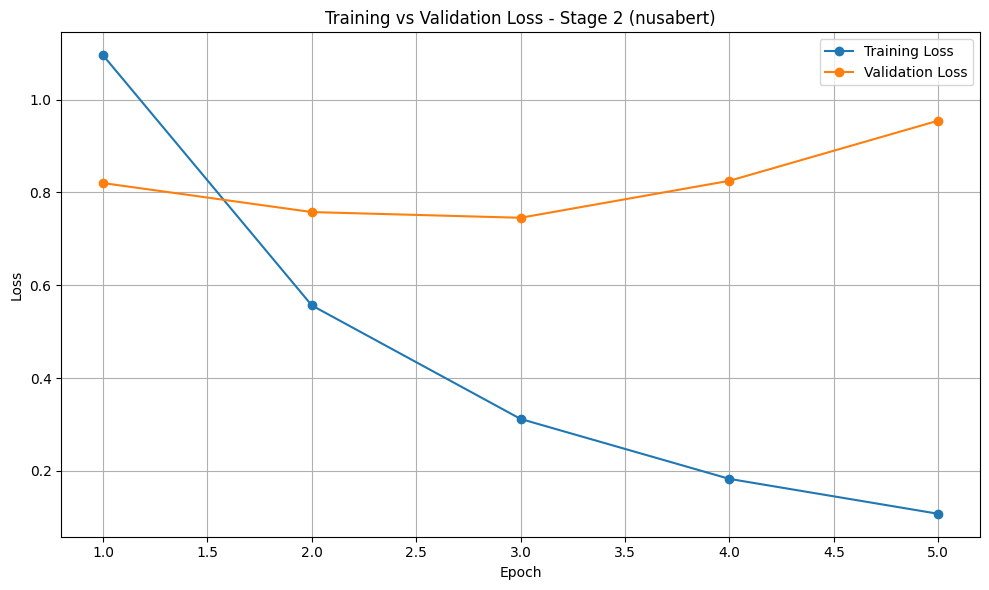

In [72]:
import matplotlib.pyplot as plt

history_s2 = trainer_s2.state.log_history

# Training loss rata-rata per epoch
train_logs_s2 = [x for x in history_s2 if 'loss' in x and 'eval_loss' not in x]
train_epochs_s2 = [x['epoch'] for x in train_logs_s2]
train_losses_s2 = [x['loss'] for x in train_logs_s2]

epoch_numbers_s2 = sorted(set(int(np.ceil(e)) for e in train_epochs_s2))
avg_train_loss_s2 = [
    np.mean([l for e, l in zip(train_epochs_s2, train_losses_s2) if int(np.ceil(e)) == ep])
    for ep in epoch_numbers_s2
]

# Validation loss per epoch (ambil yang pertama tiap epoch)
val_loss_by_epoch_s2 = {}
for x in history_s2:
    if 'eval_loss' in x:
        ep = int(round(x['epoch']))
        if ep > 0 and ep not in val_loss_by_epoch_s2:
            val_loss_by_epoch_s2[ep] = x['eval_loss']
val_epochs_s2 = sorted(val_loss_by_epoch_s2)
val_losses_s2 = [val_loss_by_epoch_s2[ep] for ep in val_epochs_s2]

plt.figure(figsize=(10, 6))
plt.plot(epoch_numbers_s2, avg_train_loss_s2, marker='o', label='Training Loss')
plt.plot(val_epochs_s2, val_losses_s2, marker='o', label='Validation Loss')
plt.title('Training vs Validation Loss - Stage 2 (nusabert)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [73]:
pred2 = trainer_s2.predict(test_dataset_2)
probs2_test = 1 / (1 + np.exp(-pred2.predictions))   # sigmoid per label
y2_true = pred2.label_ids.astype(int)

pred_label2 = (probs2_test >= 0.5).astype(int)
# pred_label2_tuned = (probs2_test >= threshold_vector_s2).astype(int)

print("Stage 2 classification report @ default threshold (0.5) -- test set:")
print(classification_report(y2_true, pred_label2, target_names=LABEL_COLS, zero_division=0))

# print(f"\nStage 2 classification report @ tuned threshold -- test set:")
# print(classification_report(y2_true, pred_label2_tuned, target_names=LABEL_COLS, zero_division=0))

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.



Stage 2 classification report @ default threshold (0.5) -- test set:
                               precision    recall  f1-score   support

                      insults       0.58      0.69      0.63       211
              identity_attack       0.60      0.71      0.65       199
threat_incitement_to_violence       0.50      0.18      0.27        22
          profanity_obscenity       0.53      0.64      0.58        72
            sexually_explicit       0.67      0.33      0.44        12

                    micro avg       0.58      0.66      0.62       516
                    macro avg       0.57      0.51      0.51       516
                 weighted avg       0.58      0.66      0.61       516
                  samples avg       0.54      0.56      0.53       516

